# TP2 — Reconstrucción 3D

**Convención global:** plano ChArUco en Z=0 y +Z hacia el zapato. Los resultados PLY, las poses y la medición utilizan este mismo sistema métrico.

## 0. Imports y configuración

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import cv2
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from src.dataset import load_stereo_pairs, read_stereo_pair
from src.calibration import load_calibration, rectify_pair
from src.stereo import compute_disparity, reproject_to_3d
from src.pose import estimate_pose, world_from_rectified
from src.pointcloud import world_pointcloud, measure_object
from src.visualization import plot_epipolar_pair, plot_disparity, plot_pose, plot_camera_poses, camera_poses_mesh, plot_measurement
from src.evaluation import epipolar_vertical_errors, board_stereo_errors, cloud_overlap

DATA_DIR = Path("data")
CAPTURE_DIR = DATA_DIR / "captures"
CALIBRATION_PATH = DATA_DIR / "stereo_calibration.pkl"
MAPS_PATH = DATA_DIR / "stereo_maps.pkl"
OUTPUT_DIR = Path("outputs")


# ChArUco, dimensiones reales en milímetros.
BOARD_GRID = (9, 13)
SQUARE_SIZE_MM = 42.0
MARKER_SIZE_MM = 31.5
ARUCO_DICTIONARY = cv2.aruco.DICT_5X5_100

# Marco global: Z positivo hacia el zapato, XY dentro de los límites del tablero.
# Rotación de 180° en X + cambio del origen a la esquina opuesta sobre Y.
BOARD_WIDTH_MM, BOARD_HEIGHT_MM = np.array(BOARD_GRID) * SQUARE_SIZE_MM
T_WORLD_BOARD = np.eye(4)
T_WORLD_BOARD[:3, :3] = np.diag([1.0, -1.0, -1.0])
T_WORLD_BOARD[1, 3] = BOARD_HEIGHT_MM

SGBM_PARAMS = {
    "min_disparity": 0,
    "num_disparities": 128,
    "block_size": 5,
    "uniqueness_ratio": 10,
}
MAX_VIEW_DEPTH_MM = 1500

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## 1. Calibración disponible

In [2]:
calibration, stereo_maps = load_calibration(CALIBRATION_PATH, MAPS_PATH)
width, height = calibration["image_size"]
print(f"Resolución: {width} × {height} px")
rvec_stereo, _ = cv2.Rodrigues(calibration["R"])
print("Rotación relativa:", rvec_stereo.ravel())
print("Traslación relativa (mm):", calibration["T"].ravel())

Resolución: 1280 × 720 px
Rotación relativa: [-0.0023639   0.01433989  0.00116572]
Traslación relativa (mm): [-5.94632400e+01 -2.81314751e-02  3.12182026e-01]


### Error de calibración estéreo

---

La calibración del sistema se realizó previamente con `i308-calib`, utilizando 14 pares de imágenes de un checkerboard de 9 × 6 esquinas internas. Mediante `cv2.stereoCalibrate()` se estimaron los parámetros intrínsecos de ambas cámaras, sus coeficientes de distorsión y la transformación rígida relativa.

Para evaluar la calidad del ajuste, se reproduce la calibración y se calcula el error cuadrático medio de reproyección (RMS), expresado en píxeles. Este indicador cuantifica la discrepancia entre las esquinas detectadas y las proyecciones predichas por el modelo calibrado.

La calibración constituye la base geométrica de la rectificación y de la posterior recuperación de profundidad, aunque un error de reproyección reducido no garantiza por sí solo una reconstrucción tridimensional precisa.

In [3]:
# Evaluación de calibración sobre el checkerboard original
CALIB_PATTERN = (9, 6)  # Esquinas internas
CALIB_SQUARE_SIZE_MM = 28.0

grid = np.zeros((np.prod(CALIB_PATTERN), 3), dtype=np.float32)
grid[:, :2] = np.mgrid[
    0:CALIB_PATTERN[0], 0:CALIB_PATTERN[1]
].T.reshape(-1, 2)
grid *= CALIB_SQUARE_SIZE_MM

flags = (
    cv2.CALIB_CB_ADAPTIVE_THRESH
    | cv2.CALIB_CB_NORMALIZE_IMAGE
    | cv2.CALIB_CB_FAST_CHECK
)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)

object_points, left_points, right_points = [], [], []

for left_path in sorted((DATA_DIR / "calib").glob("left_*.jpg")):
    right_path = left_path.with_name(left_path.name.replace("left_", "right_"))

    left = cv2.imread(str(left_path), cv2.IMREAD_GRAYSCALE)
    right = cv2.imread(str(right_path), cv2.IMREAD_GRAYSCALE)

    found_l, corners_l = cv2.findChessboardCorners(left, CALIB_PATTERN, flags)
    found_r, corners_r = cv2.findChessboardCorners(right, CALIB_PATTERN, flags)

    if not (found_l and found_r):
        continue

    corners_l = cv2.cornerSubPix(left, corners_l, (7, 7), (-1, -1), criteria)
    corners_r = cv2.cornerSubPix(right, corners_r, (7, 7), (-1, -1), criteria)

    object_points.append(grid.copy())
    left_points.append(corners_l.reshape(-1, 2))
    right_points.append(corners_r.reshape(-1, 2))

rms, _, _, _, _, _, T_est, _, _ = cv2.stereoCalibrate(
    object_points,
    left_points,
    right_points,
    None, None, None, None,
    calibration["image_size"],
    flags=0,
)

print(f"Pares utilizados: {len(object_points)}")
print(f"RMS calibración estéreo: {rms:.3f} px")
print(f"Baseline recalibrado: {np.linalg.norm(T_est):.2f} mm")
print(f"Baseline guardado: {np.linalg.norm(calibration['T']):.2f} mm")

Pares utilizados: 14
RMS calibración estéreo: 0.474 px
Baseline recalibrado: 59.50 mm
Baseline guardado: 59.46 mm


## 2. Capturas estéreo

In [4]:
stereo_pairs = load_stereo_pairs(CAPTURE_DIR)

## 3. Rectificación

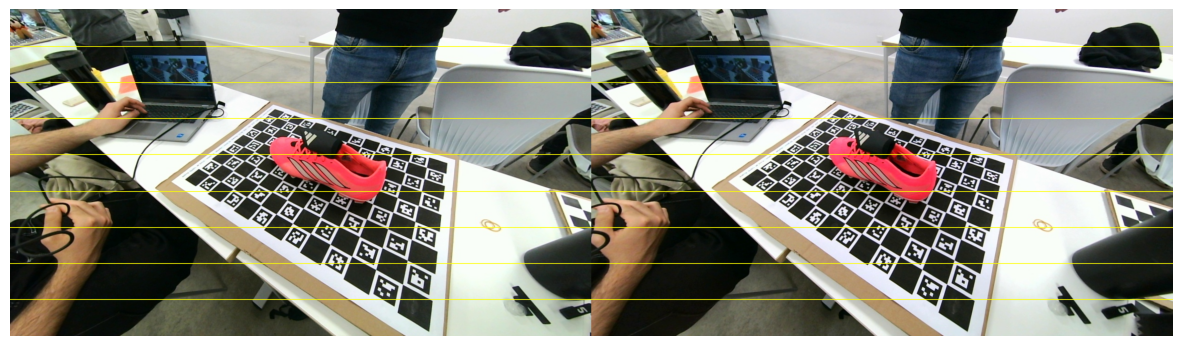

In [5]:
capture_id = list(stereo_pairs)[0]
left, right = read_stereo_pair(stereo_pairs[capture_id])
left_rect, right_rect = rectify_pair(left, right, stereo_maps)
plot_epipolar_pair(left_rect, right_rect, n_lines=8)

## 4. Disparidad y nube local

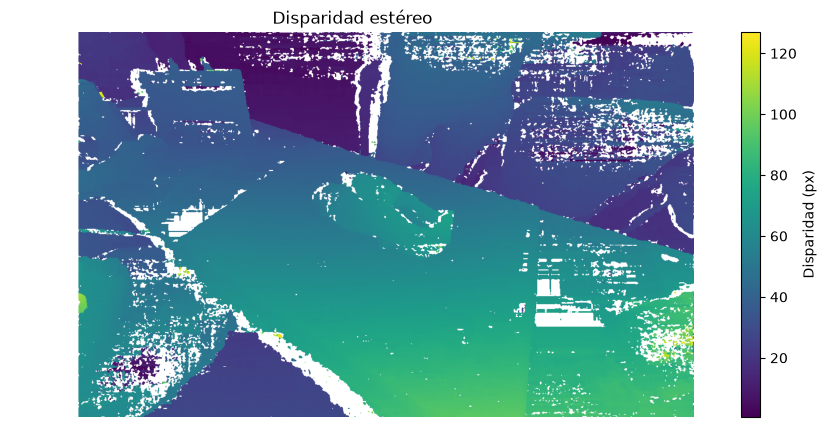

In [6]:
disparity = compute_disparity(left_rect, right_rect, **SGBM_PARAMS)
plot_disparity(disparity, SGBM_PARAMS["min_disparity"])

## 5. Pose del tablero

In [7]:
board = cv2.aruco.CharucoBoard(
    BOARD_GRID,
    SQUARE_SIZE_MM,
    MARKER_SIZE_MM,
    cv2.aruco.getPredefinedDictionary(ARUCO_DICTIONARY),
)
charuco_params = cv2.aruco.CharucoParameters()
charuco_params.cameraMatrix = calibration["left_K"]
charuco_params.distCoeffs = calibration["left_dist"]
detector = cv2.aruco.CharucoDetector(board, charuco_params)

poses = {}
for image_id, paths in stereo_pairs.items():
    image_left, _ = read_stereo_pair(paths)
    pose = estimate_pose(
        image_left, detector, calibration["left_K"], calibration["left_dist"]
    )
    if pose is not None:
        poses[image_id] = pose

print(f"Poses recuperadas: {len(poses)}/{len(stereo_pairs)}")

Poses recuperadas: 27/28


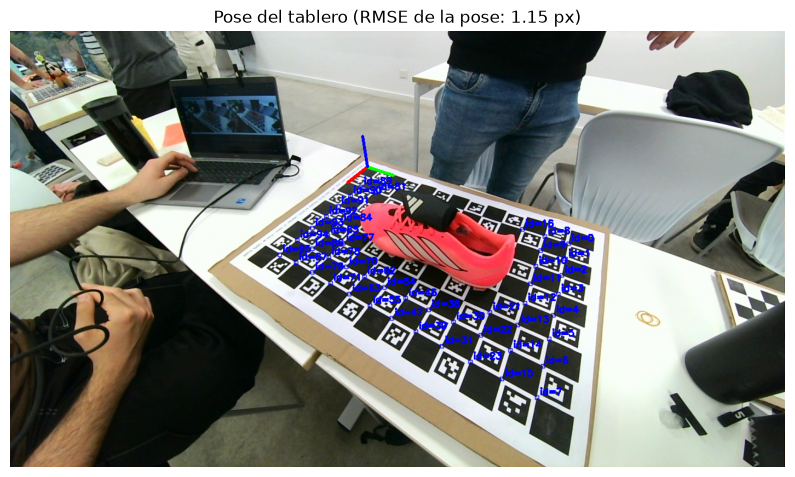

In [8]:
pose_id = next(iter(poses))
pose_left, _ = read_stereo_pair(stereo_pairs[pose_id])
plot_pose(
    pose_left, poses[pose_id], calibration["left_K"],
    calibration["left_dist"], 2 * SQUARE_SIZE_MM, T_WORLD_BOARD,
)

### Estimación de errores

---

No todos los pares estéreo presentan la misma calidad geométrica. Las diferencias en perspectiva, visibilidad del tablero, textura y distancia a las cámaras pueden afectar tanto la estimación de poses como la reconstrucción de profundidad.

Para diagnosticar estas diferencias, evaluamos cada captura mediante el RMSE de reproyección PnP, el error epipolar vertical, el residual de disparidad respecto de la predicción geométrica y la desviación tridimensional de puntos del tablero respecto de su plano conocido.

Además de los errores promedio y cuadráticos, incorporamos estadísticas robustas como la mediana, el percentil 95 y la proporción de puntos cuya desviación del plano supera los 20 mm. Estas permiten distinguir errores sistemáticos de correspondencias incorrectas aisladas, que pueden aumentar considerablemente el RMSE.

Las métricas se calculan sobre las esquinas ChArUco detectadas y sus reconstrucciones estéreo. Por lo tanto, caracterizan la consistencia geométrica del sistema sobre el tablero, pero no miden directamente la calidad de las superficies del zapato.

El objetivo es identificar capturas potencialmente problemáticas y utilizar estos resultados para diseñar experimentos de selección de vistas. La decisión final se evalúa comparando las nubes reconstruidas bajo un mismo procedimiento de fusión, filtrado y medición.

In [9]:
right_params = cv2.aruco.CharucoParameters()
right_params.cameraMatrix = calibration["right_K"]
right_params.distCoeffs = calibration["right_dist"]

right_detector = cv2.aruco.CharucoDetector(board, right_params)

results = []

for image_id in sorted(poses):
    pose = poses[image_id]
    left_i, right_i = read_stereo_pair(stereo_pairs[image_id])
    left_rect_i, right_rect_i = rectify_pair(left_i, right_i, stereo_maps)

    disparity_i = compute_disparity(left_rect_i, right_rect_i, **SGBM_PARAMS)

    right_corners, right_ids, _, _ = right_detector.detectBoard(
        cv2.cvtColor(right_i, cv2.COLOR_BGR2GRAY)
    )

    if right_ids is not None:
        epi = epipolar_vertical_errors(
            pose.corners, pose.ids, right_corners, right_ids,
            calibration, stereo_maps,
        )
    else:
        epi = np.array([])

    d_errors, plane_errors = board_stereo_errors(
        disparity_i, pose, board, calibration, stereo_maps,
        T_WORLD_BOARD, SGBM_PARAMS["min_disparity"],
    )

    results.append({
        "id": image_id,
        "corners": len(pose.ids),
        "valid": len(d_errors),
        "pnp": pose.rmse,
        "epipolar": np.sqrt(np.mean(epi**2)) if len(epi) else np.nan,
        "disparity": np.mean(np.abs(d_errors)) if len(d_errors) else np.nan,
        "disparity_median": np.median(np.abs(d_errors)),
        "plane": np.sqrt(np.mean(plane_errors**2)) if len(plane_errors) else np.nan,
        "plane_median": np.median(np.abs(plane_errors)),
        "plane_p95": np.percentile(np.abs(plane_errors), 95),
        "plane_outlier_fraction": np.mean(np.abs(plane_errors) > 20),
    })

In [10]:
print("Vista | Esquinas | Válidas | PnP px | Epi px | Disp px | Dispmed px | Plano mm | Planomed mm | Plano95 mm | out_frac")

for r in results:
    print(
        f"{r['id']:5d} | {r['corners']:8d} | {r['valid']:7d} | "
        f"{r['pnp']:6.2f} | {r['epipolar']:6.2f} | "
        f"{r['disparity']:7.2f} | {r['disparity_median']:10.2f} | {r['plane']:8.2f} | "
        f"{r['plane_median']:11.2f} | {r['plane_p95']:10.2f} | {r['plane_outlier_fraction']:8.2f} "
    )

Vista | Esquinas | Válidas | PnP px | Epi px | Disp px | Dispmed px | Plano mm | Planomed mm | Plano95 mm | out_frac
    0 |       47 |      47 |   1.15 |   0.16 |    0.52 |       0.51 |     4.00 |        3.00 |       7.27 |     0.00 
    1 |       43 |      43 |   1.68 |   0.32 |    0.45 |       0.39 |     2.07 |        1.53 |       4.02 |     0.00 
    2 |       49 |      49 |   1.47 |   0.36 |    0.84 |       0.77 |     4.05 |        3.09 |       7.70 |     0.00 
    3 |       43 |      43 |   1.51 |   0.68 |    0.78 |       0.64 |     4.28 |        3.09 |       7.88 |     0.00 
    4 |       39 |      39 |   2.70 |   1.85 |   10.96 |       0.38 |  1173.63 |        1.37 |     328.37 |     0.10 
    5 |       39 |      39 |   1.87 |   0.59 |    0.46 |       0.24 |     2.03 |        1.14 |       4.17 |     0.00 
    6 |       57 |      57 |   1.39 |   0.54 |    0.49 |       0.43 |     2.56 |        1.81 |       4.52 |     0.00 
    7 |       53 |      53 |   1.13 |   0.17 |    0.98 | 

### Análisis de errores y selección de vistas

---

Las métricas muestran una buena consistencia geométrica en la mayoría de las capturas, con errores epipolares generalmente subpíxel y desviaciones del plano ChArUco de pocos milímetros. Sin embargo, la **vista 4** presenta errores extremos de disparidad y un RMSE del plano de 1173,63 mm, aunque su mediana es de apenas 1,37 mm. Esto sugiere que el error está concentrado en unas pocas correspondencias incorrectas, mientras que la mayor parte de la reconstrucción es consistente.

Para determinar si estas anomalías afectan la reconstrucción final, realizamos los siguientes experimentos:

- **A — Referencia:** reconstrucción utilizando las vistas 0–13.
- **B — Exclusión:** reconstrucción utilizando las vistas 0–13, excluyendo la vista 4.
- **C — Sustitución:** reconstrucción utilizando las vistas 0–14, excluyendo la vista 4 e incorporando la 14, que presenta errores más homogéneos.
- **D — Fusión de vistas geométricamente consistentes:**
A partir de nuestra tabla, seleccionamos las capturas 0–22, excluyendo 4 y 19.

En los cuatro casos mantendremos los mismos parámetros de reconstrucción y filtrado, comparando las nubes finales, sus dimensiones y la cantidad de puntos conservados. Esto permitirá evaluar si la exclusión o sustitución de la vista 4 produce una mejora geométrica real.

In [11]:
VIEW_SETS = {
    "A": list(range(14)),
    "B": [i for i in range(14) if i != 4],
    "C": [i for i in range(15) if i != 4],
    "D": [i for i in range(23) if i not in (4, 19)]
}
SELECTED_VIEW_IDS = VIEW_SETS['D']
VOXEL_SIZE_MM = 3.0
OVERLAP_TOLERANCE_MM = 2 * VOXEL_SIZE_MM  # Dos vóxeles: criterio de coincidencia espacial exploratorio
ROI_MARGIN_MM = SQUARE_SIZE_MM
ROI_HEIGHT_MM = 8 * SQUARE_SIZE_MM
ROI_BELOW_MM = SQUARE_SIZE_MM
OUTLIER_NEIGHBORS = 20
OUTLIER_STD_RATIO = 2.0

# ROI del objeto: límites experimentales originales de ChArUco.
# La nueva Y se obtiene al invertir su dirección y trasladar el origen.
OBJECT_X_MM = (130.0, 270.0)
OBJECT_Y_BOARD_MM = (110.0, 445.0)
OBJECT_Y_MM = (
    BOARD_HEIGHT_MM - OBJECT_Y_BOARD_MM[1],
    BOARD_HEIGHT_MM - OBJECT_Y_BOARD_MM[0],
)
PLANE_CLEARANCE_MM = 12.0

# Separación de componentes y medición.
CLUSTER_EPS_MM = 12.0
CLUSTER_MIN_POINTS = 8
MEASUREMENT_TRIM_PERCENT = 1.0  # Extremos robustos: percentiles 1 y 99.
TRIM_SENSITIVITY_PERCENTS = (0.5, 1.0, 2.0)
FRUSTUM_DEPTH_MM = 40.0
CAMERA_LINE_RADIUS_MM = 1.0
CAMERA_AXIS_SIZE_MM = 2 * SQUARE_SIZE_MM
    

## 6. Reconstrucción y fusión de las vistas seleccionadas

Cada par estéreo se rectifica, se reconstruye mediante `Q` y se transforma desde la cámara izquierda rectificada al marco global del ChArUco (**tablero en Z=0, zapato hacia +Z**). Antes de fusionar se descartan puntos con profundidad local superior a `MAX_VIEW_DEPTH_MM`, se recorta la ROI global y se aplica un vóxel de `VOXEL_SIZE_MM`.

El conjunto de capturas se define **en la configuración inicial** mediante `SELECTED_VIEW_IDS`: A = 0–13, B = A sin 4, C = 0–14 sin 4 y D = 0–22 sin 4 y 19. Así, todos los filtros que siguen se evalúan sobre exactamente las mismas vistas en cada corrida. Las nubes individuales recortadas al zapato se conservan para las pruebas de consistencia multivista.

In [12]:
roi = o3d.geometry.AxisAlignedBoundingBox(
    np.array([-ROI_MARGIN_MM, -ROI_MARGIN_MM, -ROI_BELOW_MM]),
    np.array([
        BOARD_WIDTH_MM + ROI_MARGIN_MM,
        BOARD_HEIGHT_MM + ROI_MARGIN_MM,
        ROI_HEIGHT_MM,
    ]),
)

object_roi = o3d.geometry.AxisAlignedBoundingBox(
    np.array([OBJECT_X_MM[0], OBJECT_Y_MM[0], PLANE_CLEARANCE_MM]),
    np.array([OBJECT_X_MM[1], OBJECT_Y_MM[1], ROI_HEIGHT_MM]),
)

In [13]:
fused = o3d.geometry.PointCloud()
view_clouds = {}

for image_id in SELECTED_VIEW_IDS:
    left_i, right_i = read_stereo_pair(stereo_pairs[image_id])
    left_i, right_i = rectify_pair(left_i, right_i, stereo_maps)
    disparity_i = compute_disparity(left_i, right_i, **SGBM_PARAMS)
    points_i, colors_i = reproject_to_3d(
        disparity_i, left_i, stereo_maps["Q"], SGBM_PARAMS["min_disparity"]
    )
    valid = (points_i[:, 2] > 0) & (points_i[:, 2] <= MAX_VIEW_DEPTH_MM)

    T_world_rect = world_from_rectified(
        poses[image_id], stereo_maps["R1"], T_WORLD_BOARD
    )
    cloud_i = world_pointcloud(points_i[valid], colors_i[valid], T_world_rect, roi)
    cloud_i = cloud_i.voxel_down_sample(VOXEL_SIZE_MM)

    view_clouds[image_id] = cloud_i.crop(object_roi)
    fused += cloud_i

fused = fused.voxel_down_sample(VOXEL_SIZE_MM)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
o3d.io.write_point_cloud(str(OUTPUT_DIR / "preview_roi.ply"), fused, write_ascii=False)
print(f"ROI fusionada: {len(fused.points):,} puntos")

ROI fusionada: 251,723 puntos


### 6.1. Consistencia espacial entre vistas

Comparamos pares consecutivos de **vistas seleccionadas** con vecinos más cercanos en ambas direcciones. `overlap_fraction` indica la fracción de puntos con un vecino a menos de `OVERLAP_TOLERANCE_MM`; las distancias mediana y P95 se calculan solo entre esos puntos cercanos. El solapamiento depende también de la cobertura y las oclusiones, por lo que **no mide de manera aislada el error de pose**.

In [14]:
overlaps = []
for previous_id, image_id in zip(SELECTED_VIEW_IDS, SELECTED_VIEW_IDS[1:]):
    metrics = cloud_overlap(
        view_clouds[previous_id], view_clouds[image_id], OVERLAP_TOLERANCE_MM
    )
    overlaps.append(metrics["overlap_fraction"])
    print(
        f"{previous_id:2d} | {image_id:2d}: "
        f"cobertura={metrics['overlap_fraction']:.1%}, "
        f"mediana={metrics['matched_median_mm']:.2f} mm, "
        f"P95={metrics['matched_p95_mm']:.2f} mm"
    )

print(f"Solapamiento mediano entre pares: {np.median(overlaps):.1%}")

 0 |  1: cobertura=79.4%, mediana=2.44 mm, P95=5.32 mm
 1 |  2: cobertura=73.8%, mediana=2.47 mm, P95=5.39 mm
 2 |  3: cobertura=73.6%, mediana=2.41 mm, P95=5.37 mm
 3 |  5: cobertura=67.3%, mediana=3.03 mm, P95=5.62 mm
 5 |  6: cobertura=46.5%, mediana=3.76 mm, P95=5.72 mm
 6 |  7: cobertura=52.9%, mediana=2.65 mm, P95=5.54 mm
 7 |  8: cobertura=73.1%, mediana=2.79 mm, P95=5.53 mm
 8 |  9: cobertura=76.7%, mediana=2.12 mm, P95=5.20 mm
 9 | 10: cobertura=46.6%, mediana=2.84 mm, P95=5.53 mm
10 | 11: cobertura=60.1%, mediana=2.68 mm, P95=5.40 mm
11 | 12: cobertura=62.1%, mediana=2.79 mm, P95=5.49 mm
12 | 13: cobertura=73.2%, mediana=2.47 mm, P95=5.46 mm
13 | 14: cobertura=58.6%, mediana=3.38 mm, P95=5.64 mm
14 | 15: cobertura=73.8%, mediana=2.50 mm, P95=5.45 mm
15 | 16: cobertura=81.4%, mediana=2.02 mm, P95=5.14 mm
16 | 17: cobertura=77.1%, mediana=2.09 mm, P95=5.21 mm
17 | 18: cobertura=83.8%, mediana=1.83 mm, P95=5.14 mm
18 | 20: cobertura=52.1%, mediana=3.05 mm, P95=5.65 mm
20 | 21: c

## 7. Experimento de referencia — filtrado original

Se conserva el procedimiento inicial para poder comparar con A/B/C/D: limpieza estadística sobre **toda la ROI fusionada**, recorte del zapato y selección del clúster principal mediante DBSCAN.

- **SOR global:** `OUTLIER_NEIGHBORS` vecinos y umbral `OUTLIER_STD_RATIO` sobre la distancia media a vecinos.
- **Segmentación:** caja `object_roi`, que excluye el plano del tablero mediante `PLANE_CLEARANCE_MM`.
- **DBSCAN:** `CLUSTER_EPS_MM` y `CLUSTER_MIN_POINTS`; elimina componentes pequeñas, pero puede conservar estructuras erróneas conectadas al objeto.

Guardamos las etapas intermedias para inspección, sin confundir este resultado con el final seleccionado.

In [15]:
cleaned, _ = fused.remove_statistical_outlier(
    nb_neighbors=OUTLIER_NEIGHBORS,
    std_ratio=OUTLIER_STD_RATIO,
)
object_cloud = cleaned.crop(object_roi)

labels = np.asarray(object_cloud.cluster_dbscan(
    eps=CLUSTER_EPS_MM, min_points=CLUSTER_MIN_POINTS
))
main_cluster = np.bincount(labels[labels >= 0]).argmax()
clustered = object_cloud.select_by_index(np.flatnonzero(labels == main_cluster))

for name, cloud in (
    ("preview_clean.ply", cleaned),
    ("preview_object.ply", object_cloud),
    ("preview_clustered.ply", clustered),
):
    o3d.io.write_point_cloud(str(OUTPUT_DIR / name), cloud, write_ascii=False)

print(
    f"ROI {len(fused.points):,} -> Clean {len(cleaned.points):,} -> "
    f"Objeto {len(object_cloud.points):,} -> Cluster {len(clustered.points):,}"
)

ROI 251,723 -> Clean 246,195 -> Objeto 35,937 -> Cluster 35,783


## 8. Experimento de limpieza localizada

Como alternativa al filtrado global, recortamos primero el zapato y aplicamos SOR, filtrado por vecinos dentro de un radio y DBSCAN más estricto. Se conserva como **experimento**, porque una estructura incorrecta suficientemente densa puede sobrevivir a los tres criterios.

Para distinguir las variantes, el umbral SOR local es 1,5; el radio de vecindad equivale a dos vóxeles (mínimo de seis vecinos), y la conectividad DBSCAN usa tres vóxeles. Estos parámetros son  experimentales, no incertidumbres físicas de la cámara.

In [16]:
object_raw = fused.crop(object_roi)

local_clean, _ = object_raw.remove_statistical_outlier(
    nb_neighbors=OUTLIER_NEIGHBORS,
    std_ratio=1.5,
)
radius_clean, _ = local_clean.remove_radius_outlier(
    nb_points=6,
    radius=2 * VOXEL_SIZE_MM,
)
labels = np.asarray(radius_clean.cluster_dbscan(
    eps=3 * VOXEL_SIZE_MM,
    min_points=CLUSTER_MIN_POINTS,
))
main_cluster = np.bincount(labels[labels >= 0]).argmax()
candidate = radius_clean.select_by_index(np.flatnonzero(labels == main_cluster))

o3d.io.write_point_cloud(
    str(OUTPUT_DIR / "preview_local_clean.ply"), candidate, write_ascii=False
)
print(
    f"Objeto inicial {len(object_raw.points):,} -> "
    f"SOR local {len(local_clean.points):,} -> "
    f"Radio {len(radius_clean.points):,} -> "
    f"Cluster {len(candidate.points):,}"
)

Objeto inicial 37,000 -> SOR local 35,673 -> Radio 34,802 -> Cluster 34,556


## 9. Experimento de consistencia multivista

Una nube densa y conectada puede ser geométricamente falsa. Por eso incorporamos un criterio distinto: **cada punto debe tener un vecino a no más de dos vóxeles de distancia, procedente de otra captura**. El recuento corresponde al número de *vistas adicionales independientes*, no al número total de puntos vecinos.

Comparamos `MIN_OTHER_VIEWS` = 1, 2 y **3** sobre las mismas nubes individuales y elegimos **3** para la reconstrucción final, por la mejora visual observada. Esto equivale a requerir soporte de al menos cuatro vistas en total. No garantiza exactitud absoluta y puede eliminar regiones reales vistas desde pocas cámaras.

In [17]:
from scipy.spatial import cKDTree

SUPPORT_RADIUS_MM = 2 * VOXEL_SIZE_MM
SUPPORT_LEVELS = (1, 2, 3)
MIN_OTHER_VIEWS = 3

trees = {
    image_id: cKDTree(np.asarray(cloud.points))
    for image_id, cloud in view_clouds.items()
}

support_counts = {}
for image_id, cloud in view_clouds.items():
    points = np.asarray(cloud.points)
    counts = np.zeros(len(points), dtype=int)

    for other_id, tree in trees.items():
        if image_id == other_id:
            continue
        distances, _ = tree.query(points, distance_upper_bound=SUPPORT_RADIUS_MM)
        counts += np.isfinite(distances)

    support_counts[image_id] = counts

In [18]:
support_clouds = {}

for min_views in SUPPORT_LEVELS:
    cloud = o3d.geometry.PointCloud()
    for image_id, view in view_clouds.items():
        indices = np.flatnonzero(support_counts[image_id] >= min_views)
        cloud += view.select_by_index(indices)

    cloud = cloud.voxel_down_sample(VOXEL_SIZE_MM)
    support_clouds[min_views] = cloud
    print(f"Soporte de {min_views} vistas adicionales: {len(cloud.points):,} puntos")

    preview_name = (
        "preview_multiview.ply" if min_views == MIN_OTHER_VIEWS
        else f"preview_support_{min_views}.ply"
    )
    o3d.io.write_point_cloud(
        str(OUTPUT_DIR / preview_name), cloud, write_ascii=False
    )

supported = support_clouds[MIN_OTHER_VIEWS]

Soporte de 1 vistas adicionales: 30,369 puntos
Soporte de 2 vistas adicionales: 28,158 puntos
Soporte de 3 vistas adicionales: 29,009 puntos


### 9.1. Inspección opcional por cámara

Cada vista se colorea artificialmente para identificar qué cámaras contribuyen a las agrupaciones de ruido. Esta exportación **no se usa en la reconstrucción final**.

In [19]:
colored_views = o3d.geometry.PointCloud()
cmap = plt.get_cmap("tab20", len(view_clouds))

for k, (view_id, cloud) in enumerate(view_clouds.items()):
    colored = o3d.geometry.PointCloud(cloud)
    colored.paint_uniform_color(cmap(k)[:3])
    colored_views += colored

o3d.io.write_point_cloud(
    str(OUTPUT_DIR / "preview_by_view.ply"), colored_views, write_ascii=False
)
print("PLY de vistas coloreadas:", OUTPUT_DIR / "preview_by_view.ply")

PLY de vistas coloreadas: outputs/preview_by_view.ply


## 10. Comparación de filtros

Comparamos **todas las variantes**, sin volver a calcular ni duplicar las reconstrucciones: filtrado original, filtrado local y soporte multivista de 1/2/3 vistas adicionales. Para cada nube evaluamos cantidad de puntos y dimensiones con los mismos percentiles de recorte.

Estas variaciones miden **sensibilidad del estimador**. No equivalen a errores frente a dimensiones físicas reales. A partir de la inspección visual de los ensayos, la salida elegida es `supported` con `MIN_OTHER_VIEWS=3`, fue la que mejores resultados dio. Las figuras y el PLY final de las secciones siguientes utilizan exclusivamente esa versión.

In [20]:
variants = {
    "SOR global + DBSCAN": clustered,
    "SOR local + radio + DBSCAN": candidate,
    **{f"Soporte multivista ≥{k}": support_clouds[k] for k in SUPPORT_LEVELS},
}

for name, cloud in variants.items():
    print(f"  {name}: {len(cloud.points):,}")


final_cloud = supported

  SOR global + DBSCAN: 35,783
  SOR local + radio + DBSCAN: 34,556
  Soporte multivista ≥1: 30,369
  Soporte multivista ≥2: 28,158
  Soporte multivista ≥3: 29,009


## 11. Validación geométrica y cámaras en el marco global

Se visualizan el tablero ChArUco, las poses recuperadas y los frustums de las vistas seleccionadas. La nube representada es **`final_cloud`**; no la salida del filtrado original. La matriz `R1` y el cambio rígido `T_WORLD_BOARD` aseguran que las cámaras y la nube compartan el mismo marco.

Exportamos una malla PLY independiente con cámaras y ejes para abrirla en MeshLab junto con `shoe_final.ply`, sin agregar geometría artificial a la nube del zapato.

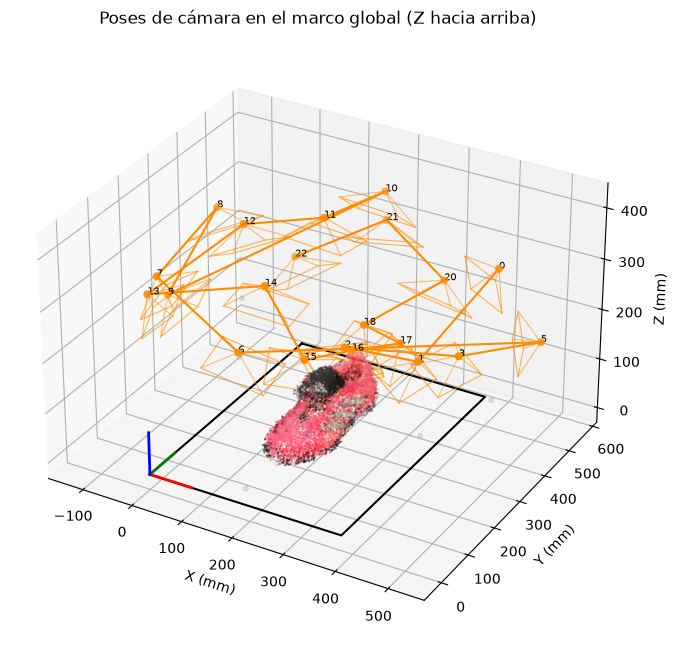

True

In [21]:
fig = plot_camera_poses(
    poses, SELECTED_VIEW_IDS, stereo_maps["R1"], T_WORLD_BOARD,
    stereo_maps["P1"][:3, :3], calibration["image_size"],
    board_size_mm=np.array(BOARD_GRID) * SQUARE_SIZE_MM,
    cloud=final_cloud, frustum_depth_mm=FRUSTUM_DEPTH_MM,
)
fig.savefig(OUTPUT_DIR / "camera_poses.png", dpi=170, bbox_inches="tight")
plt.show()

camera_mesh = camera_poses_mesh(
    poses, SELECTED_VIEW_IDS, stereo_maps["R1"], T_WORLD_BOARD,
    stereo_maps["P1"][:3, :3], calibration["image_size"],
    (BOARD_WIDTH_MM, BOARD_HEIGHT_MM),
    FRUSTUM_DEPTH_MM, CAMERA_LINE_RADIUS_MM, CAMERA_AXIS_SIZE_MM,
)
o3d.io.write_triangle_mesh(
    str(OUTPUT_DIR / "camera_poses.ply"), camera_mesh, write_ascii=False
)

## 12. Medición final y exportación de referencia (SGBM)

La dirección de largo se obtiene mediante PCA sobre XY, el ancho es su perpendicular y la altura se mide respecto del plano ChArUco Z=0. Los percentiles `MEASUREMENT_TRIM_PERCENT` limitan la influencia de extremos sin recuperar las regiones no observadas.

Los resultados impresos y la caja representada corresponden exclusivamente a **`final_cloud` (soporte multivista de 3 vistas adicionales)**. Se exporta un PLY binario del zapato y la figura de medición. Los demás PLY se conservan únicamente para documentar los experimentos de filtrado.

Largo: 284.6 mm · Ancho: 96.7 mm · Alto: 114.3 mm


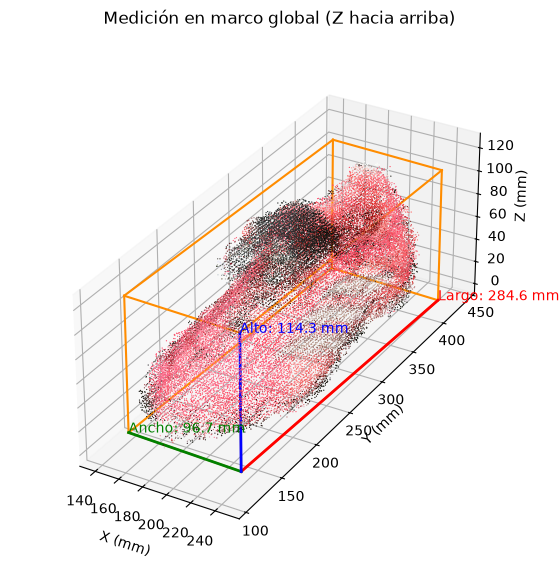

Nube final: 29,009 puntos | outputs/shoe_final.ply


In [22]:
dimensions, measurement_box = measure_object(
    final_cloud, trim_percent=MEASUREMENT_TRIM_PERCENT
)
print(
    f"Largo: {dimensions['length_mm']:.1f} mm · "
    f"Ancho: {dimensions['width_mm']:.1f} mm · "
    f"Alto: {dimensions['height_mm']:.1f} mm"
)

fig = plot_measurement(final_cloud, measurement_box)
fig.savefig(OUTPUT_DIR / "measurement_sgbm.png", dpi=170, bbox_inches="tight")
plt.show()

final_path = OUTPUT_DIR / "shoe_final.ply"
o3d.io.write_point_cloud(str(final_path), final_cloud, write_ascii=False)
print(f"Nube final: {len(final_cloud.points):,} puntos | {final_path}")

## 13. Reconstrucción definitiva con CREStereo

Tras evaluar StereoSGBM con las selecciones A–D, adoptamos
CREStereo por la mejor calidad visual de la reconstrucción.

Utilizamos todas las capturas con pose ChArUco válida (27 de 28).
Se conservan la calibración, las transformaciones geométricas
y las regiones de interés del pipeline anterior.

La limpieza final requiere soporte de al menos tres vistas
adicionales dentro de un radio de 6 mm. Después se aplica SOR
con 20 vecinos y `std_ratio=1.5`, seguido de una voxelización
de 3 mm.

Exportamos la nube definitiva como `shoe_final_dl.ply`.

In [23]:
from urllib.request import urlretrieve
from scipy.spatial import cKDTree
from src.stereo_neural import CREStereo

dl_views = sorted(poses)
model_path = Path("models/crestereo_combined_iter10_720x1280.onnx")
model_path.parent.mkdir(parents=True, exist_ok=True)
if not model_path.exists():
    urlretrieve(
        "https://github.com/nburrus/stereodemo/releases/download/"
        "v0.1-crestereo/crestereo_combined_iter10_720x1280.onnx",
        model_path,
    )

crestereo = CREStereo(model_path)
view_clouds_dl = {}

for image_id in dl_views:
    left, right = read_stereo_pair(stereo_pairs[image_id])
    left_rect, right_rect = rectify_pair(left, right, stereo_maps)
    disparity_dl = crestereo.compute_disparity(left_rect, right_rect)
    points, colors = reproject_to_3d(
        disparity_dl, left_rect, stereo_maps["Q"], SGBM_PARAMS["min_disparity"]
    )
    valid = (points[:, 2] > 0) & (points[:, 2] <= MAX_VIEW_DEPTH_MM)
    if image_id == 0: 
        disparity_dl_example = disparity_dl.copy() # Para plot de mapa
        local_points = points[valid]
        local_colors = colors[valid]

        local_cloud_example = o3d.geometry.PointCloud()
        local_cloud_example.points = o3d.utility.Vector3dVector(local_points)
        local_cloud_example.colors = o3d.utility.Vector3dVector(
            local_colors.astype(np.float32) / 255.0
        )

        local_cloud_example = local_cloud_example.voxel_down_sample(VOXEL_SIZE_MM)

        o3d.io.write_point_cloud(
            str(OUTPUT_DIR / "local_cloud_dl_example.ply"),
            local_cloud_example,
            write_ascii=False,
        )
    T_world_rect = world_from_rectified(
        poses[image_id], stereo_maps["R1"], T_WORLD_BOARD
    )
    cloud = world_pointcloud(points[valid], colors[valid], T_world_rect, roi)
    cloud = cloud.voxel_down_sample(VOXEL_SIZE_MM)
    view_clouds_dl[image_id] = cloud.crop(object_roi)

# Mismo criterio: cada punto necesita 3 vistas adicionales a <= 6 mm.
trees = {
    image_id: cKDTree(np.asarray(cloud.points))
    for image_id, cloud in view_clouds_dl.items()
}
supported_dl = o3d.geometry.PointCloud()

for image_id, cloud in view_clouds_dl.items():
    points = np.asarray(cloud.points)
    support = np.zeros(len(points), dtype=int)
    for other_id, tree in trees.items():
        if image_id != other_id:
            distances, _ = tree.query(
                points, distance_upper_bound=SUPPORT_RADIUS_MM
            )
            support += np.isfinite(distances)
    supported_dl += cloud.select_by_index(
        np.flatnonzero(support >= MIN_OTHER_VIEWS)
    )

# Limpieza estadística sobre la nube multivista
sor_dl, _ = supported_dl.remove_statistical_outlier(
    nb_neighbors=OUTLIER_NEIGHBORS,
    std_ratio=1.5,
)
cleaned_dl = sor_dl.voxel_down_sample(VOXEL_SIZE_MM)

raw_dl = o3d.geometry.PointCloud()
for cloud in view_clouds_dl.values():
    raw_dl += cloud

for name, cloud in (
    ("preview_object_dl.ply", raw_dl),
    ("preview_support_dl.ply", supported_dl),
    ("shoe_final_dl.ply", cleaned_dl),
):
    o3d.io.write_point_cloud(
        str(OUTPUT_DIR / name), cloud, write_ascii=False
    )

print(f"ROI del objeto (suma por vista): {sum(len(c.points) for c in view_clouds_dl.values()):,}")
print(f"Soporte multivista: {len(supported_dl.points):,}")
print(f"Después de SOR: {len(sor_dl.points):,}")
print(f"Voxelización final: {len(cleaned_dl.points):,}")

ROI del objeto (suma por vista): 144,167
Soporte multivista: 135,961
Después de SOR: 126,951
Voxelización final: 24,037


Largo: 283.6 mm · Ancho: 92.7 mm · Alto: 114.0 mm


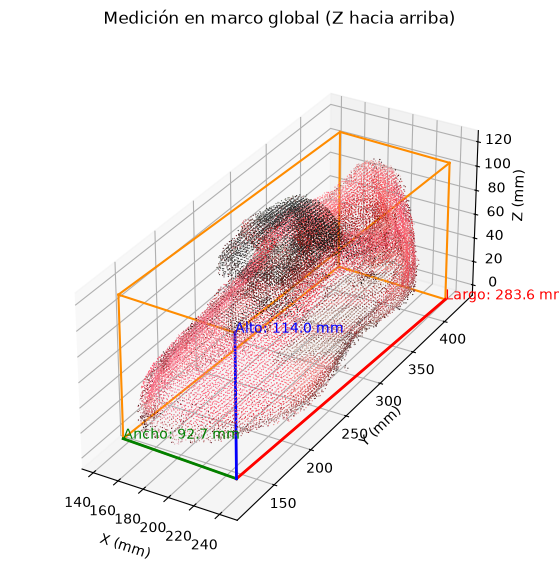

In [24]:
dimensions, measurement_box = measure_object(
    cleaned_dl, trim_percent=MEASUREMENT_TRIM_PERCENT
)
print(
    f"Largo: {dimensions['length_mm']:.1f} mm · "
    f"Ancho: {dimensions['width_mm']:.1f} mm · "
    f"Alto: {dimensions['height_mm']:.1f} mm"
)

fig = plot_measurement(cleaned_dl, measurement_box)
fig.savefig(OUTPUT_DIR / "measurement_crestereo.png", dpi=170, bbox_inches="tight")
plt.show()

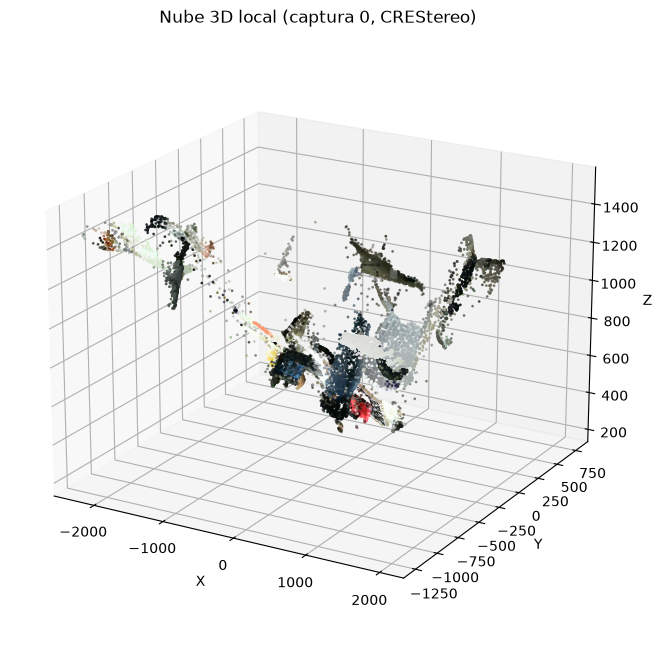

In [25]:
local_points = np.asarray(local_cloud_example.points)
local_colors = np.asarray(local_cloud_example.colors)

sample_idx = np.arange(0, len(local_points), max(1, len(local_points) // 15000))
sample_points = local_points[sample_idx]
sample_colors = local_colors[sample_idx]

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(
    sample_points[:, 0],
    sample_points[:, 1],
    sample_points[:, 2],
    c=sample_colors,
    s=1,
)

ax.set_title("Nube 3D local (captura 0, CREStereo)")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.view_init(elev=20, azim=-60)

fig.savefig(
    OUTPUT_DIR / "local_cloud_dl_example.png",
    dpi=170,
    bbox_inches="tight",
)
plt.show()

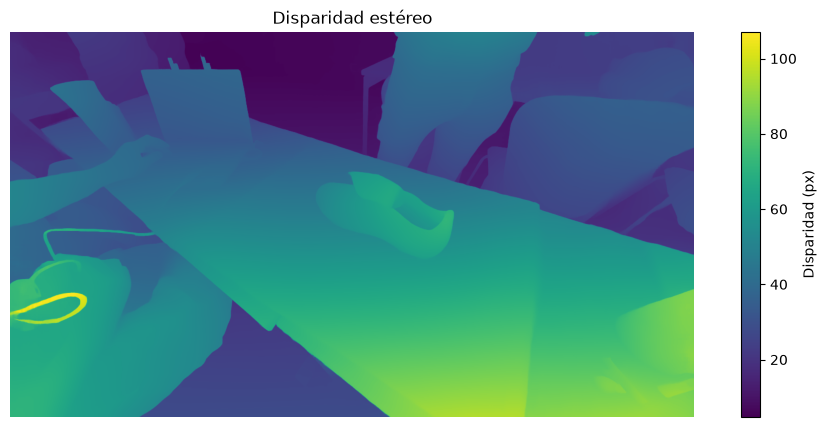

In [26]:
plot_disparity(disparity_dl_example, SGBM_PARAMS["min_disparity"])

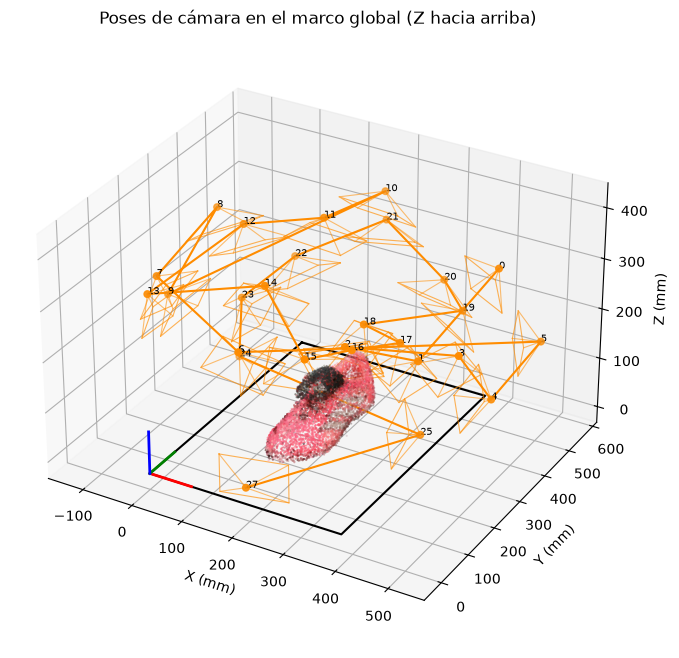

In [ ]:
fig = plot_camera_poses(
    poses,
    dl_views,
    stereo_maps["R1"],
    T_WORLD_BOARD,
    stereo_maps["P1"][:3, :3],
    calibration["image_size"],
    board_size_mm=np.array(BOARD_GRID) * SQUARE_SIZE_MM,
    cloud=cleaned_dl,
    frustum_depth_mm=FRUSTUM_DEPTH_MM,
)

fig.savefig(OUTPUT_DIR / "camera_poses_dl.png", dpi=170, bbox_inches="tight")
plt.show()

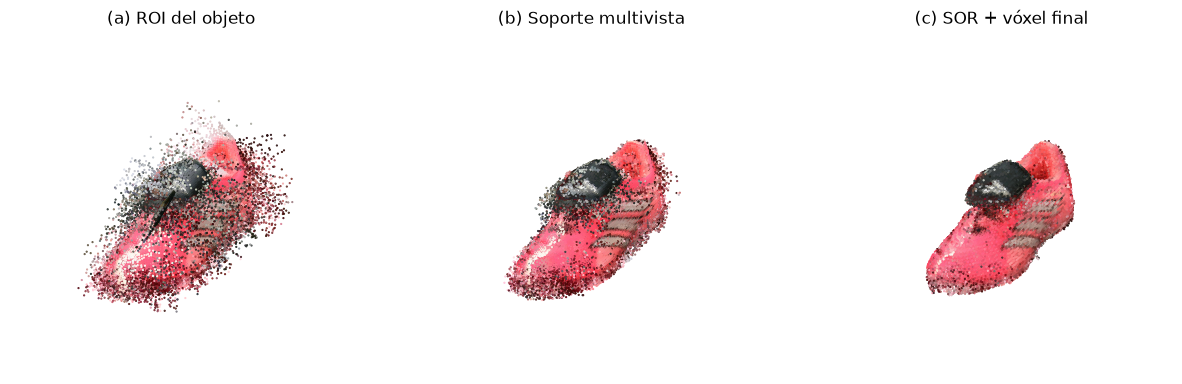

In [29]:
clouds = [
    (title, o3d.io.read_point_cloud(str(OUTPUT_DIR / filename)))
    for title, filename in (
        ("(a) ROI del objeto", "preview_object_dl.ply"),
        ("(b) Soporte multivista", "preview_support_dl.ply"),
        ("(c) SOR + vóxel final", "shoe_final_dl.ply"),
    )
]

all_points = np.vstack([np.asarray(cloud.points) for _, cloud in clouds])
mins, maxs = all_points.min(axis=0), all_points.max(axis=0)

# Límites idénticos para las tres nubes
margin = 0.05 * (maxs - mins)
limits = np.column_stack((mins - margin, maxs + margin))

fig = plt.figure(figsize=(15, 5))

for i, (title, cloud) in enumerate(clouds, start=1):
    points = np.asarray(cloud.points)
    colors = np.asarray(cloud.colors)

    ax = fig.add_subplot(1, 3, i, projection="3d")
    ax.scatter(*points.T, c=colors, s=0.3, depthshade=False)

    ax.set(xlim=limits[0], ylim=limits[1],
           zlim=limits[2], title=title)
    ax.set_box_aspect(limits[:, 1] - limits[:, 0])
    ax.set_proj_type("ortho")
    ax.view_init(elev=25, azim=-65)
    ax.set_axis_off()

Path("figures").mkdir(exist_ok=True)
fig.savefig(OUTPUT_DIR / "nube_optimizacion.png", dpi=200, bbox_inches="tight")
plt.show()
